# 11 · Baselines

Los baselines son las referencias con las que se comparan los modelos. Los baselines evalúan en validación y en test, igual que
los modelos, para poder compararse con ellos.

1. Baselines a plantear
2. B0: el ERP acierta
3. B1: corrección del sesgo global
4. B2: tabla de consulta por grupo
5. Escalera de baselines

- **Entrada:** `data/modeling/df_split.parquet` y `data/modeling/folds.csv`
- **Salida:** `data/predictions/b0.parquet`, `b1.parquet`, `b2.parquet` y `results/tables/escalera_baselines.csv`

In [169]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.modelado import bloques_evaluacion, cargar_datos_modelado, metricas, obtener_fold
from src.rutas import FIGURES, PREDICTIONS, TABLES

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 1. Baselines a plantear

Un baseline es una predicción simple que sirve de referencia, permitirá evaluar el desempeño de los modelos frente reglas sencillas. Se plantean tres baselines, de menos a más información:

| Baseline | Predicción para cada fase | Usa variables (x) |
|---|---|---|
| **B0** | ratio = 1 | No |
| **B1** | ratio = una constante calculada con el train (mediana o media) | No |
| **B2** | ratio = la constante de su grupo (familia de máquinas o máquina), calculada con el train | Sí, una |

### B0: el ERP acierta

Predice ratio = 1 en todas las fases, es decir, que el tiempo real coincide con el planificado. Es la planificación actual tal como está definida en el ERP. No es necesario realizar ningún cálculo adicional. 

### B1: el ERP tiene un sesgo fijo

El valor del ratio se calcula y se predice el mismo valor para todas las fases.  la constante que mejor resume el train. Si todas las fases tienen una desviación sistemática, B1 la corrige, y cualquier modelo aprenderá también ese sesgo.

Se calculan dos versiones, porque cada métrica tiene su constante óptima:

- **B1-mediana**: la mediana es la constante que minimiza el MAE → se evalúa con MAE.
- **B1-media**: la media es la constante que minimiza el RMSE → se evalúa con RMSE.

> Este notebook presentara la distribución del ratio como asimétrica (pocas fases con ratio elevado inflan la media). Por esto se determina que la mediana representa mejor a la "fase típica". Por eso B1-mediana es la referencia principal.

B0 y B1 ignoran por completo las variables de entrada, no saben qué máquina se usa, ni la fase, ni la cantidad.

### B2: una tabla de consulta por grupo

Ahora ya se emplean algunas variables de entrada. Cada fase recibe la mediana (o la media) del ratio de su grupo en el train. Como símil práctico es la tabla que podría construir un planificador en una hoja de cálculo. Se generan dos versiones:

- **B2-familia**: calcular el valor por familia de máquinas.
- **B2-máquina**: calcular el valor por máquina.

Si un grupo/maquina tiene menos de 30 fases en train, o no aparece, su valor no es fiable y la fase recibe la constante de B1 (fallback, detallado en el apartado `4`).

### Qué pregunta responde cada uno

```text
B0 (ERP) ──► B1 (corrijo sesgo global) ──► B2 (tabla por grupo) ──► Modelo ML
  │                 │                              │                    │
  └ ¿ERP sesgado? ──┘                              │                    │
                    └ ¿las variables aportan algo? ┘                    │
                                                   └ ¿compensa el ML? ──┘
```

Si los modelos no superan a B2, hay señal en los datos, pero una tabla simple la captura casi toda. 

### Cómo se evalúan

B0 no calcula nada: siempre predice 1.      
      
B1 y B2 sí calculan valores (una mediana, una media o una tabla por grupo), y esos valores se obtienen **solo con el train** de cada bloque. Si se calcularan con todo el dataset, el baseline "conocería" el periodo que evalúa: sería leakage, igual que en un modelo.

| Bloque | Cálculo | Evaluación |
|---|---|---|
| Fold 1 | jun 2025 – ene 2026 | feb 2026 |
| Fold 2 | jun 2025 – feb 2026 | mar 2026 |
| Fold 3 | jun 2025 – mar 2026 | abr 2026 |
| Test | todo desarrollo (jun 2025 – abr 2026) | may – jul 2026 |

En cada bloque se mide el MAE (versiones con mediana) y el RMSE (versiones con media), y se comparan con el error de los modelos en ese mismo bloque.

In [170]:
df, MESES_VALIDACION = cargar_datos_modelado()
print(df.shape)
print("Meses de validación:", MESES_VALIDACION)

(14146, 15)
Meses de validación: ['2026-02', '2026-03', '2026-04']


## 2. B0

El B0 supone que el ratio = 1: el ERP acierta.

Este no se entrena, predice 1 para todas las fases. Lo que hay que hacer es medir su error en los mismos datos donde
mediremos los modelos. Trabajaremos con las dos métricas de error, MAE y RMSE, para evaluar la diferencia.

> Interesa medir cuánto se equivoca esa regla en validación.

In [171]:
# Predicción de B0: ratio = 1 para todas las fases (el tiempo real = el teórico)
df_B0 = df.copy()
df_B0["pred_B0"] = 1.0

# Error de B0 en cada mes de validación y en test (B0 no entrena: solo se usa el bloque a evaluar)
filas = []
for bloque, _, evaluar in bloques_evaluacion(df_B0, MESES_VALIDACION):
    filas.append({"bloque": bloque, **metricas(evaluar["ratio"], evaluar["pred_B0"])})

resultados_B0 = pd.DataFrame(filas)
resultados_B0.round(3)

,bloque,MAE,RMSE,n
0,valid 2026-02,1.140,1.779,915
1,valid 2026-03,1.086,1.672,993
2,valid 2026-04,1.092,1.680,963
3,test,1.019,1.585,2385


Los resultados son estables entre meses, además los valores de MAE y RMSE son notablemente altos.

- **MAE.** Se mantiene en torno a 1,1. Esto supone que de media el tiempo real se aleja del teórico en un 110 % del tiempo teórico. El MAE no tiene signo, así que no indica si el ERP se queda corto o se pasa. Conectando con la revisión del ratio, donde se vieron ratios de hasta 8 unidades, podría ser que el ERP se esté quedando corto en sus tiempos teóricos, pero no se puede confirmar todavía.
     
- **RMSE.** Se mantiene en torno a 1,6. Su valor es mayor que el del MAE: el RMSE es sensible a fallos grandes, esto indica que los tiempos teóricos contienen errores grandes. 
    
La separación entre MAE y RMSE remarca el hecho de que hay errores grandes en la planificación: el error no es homogéneo, hay fases que se equivocan poco y algunas que se equivocan mucho. Esto encaja con el estudio de las colas del ratio, donde un grupo de fases mantenía valores muy altos sin ser outliers. 

Estos resultados hay que mirarlos con profundidad. Un MAE alto puede deberse a dos cosas: sesgo o dispersión en la planificación.

> ¿El error de B0 es sesgo o dispersión?

In [172]:
filas = []
for bloque, _, d in bloques_evaluacion(df_B0, MESES_VALIDACION):
    filas.append({
        "bloque":        bloque,
        "error_medio":   (d["pred_B0"] - d["ratio"]).mean(),
        "mediana_ratio": d["ratio"].median(),
        "%_ratio>1":     (d["ratio"] > 1).mean() * 100,
        "media_ratio":   d["ratio"].mean(),
        "diferencia":    d["ratio"].mean() - d["ratio"].median(),
    })

sesgo_B0 = pd.DataFrame(filas).round(3)
display(sesgo_B0)

,bloque,error_medio,mediana_ratio,%_ratio>1,media_ratio,diferencia
0,valid 2026-02,-1.008,1.539,75.082,2.008,0.469
1,valid 2026-03,-0.959,1.584,78.852,1.959,0.375
2,valid 2026-04,-0.940,1.533,74.455,1.940,0.406
3,test,-0.883,1.489,75.262,1.883,0.395


Estos resultados apuntan a un sesgo: el ERP se queda corto en sus estimaciones de tiempo. Aproximadamente el 75 % de las fases tienen un ratio superior a 1, esto es 3 de cada 4 fases tardan más de lo planificado. La mediana, con un ratio de 1,5 indica que el tiempo real de una fase típica supera en un 50 % al teórico. El error medio se ha calculado como `ratio_ERP − ratio_real`; que se mantenga en torno a −0,9 refuerza que haya un sesgo hacia un tiempo teórico menor que el real. Estos resultados son estables en el tiempo.

Analizando la relación entre la media y la mediana del ratio, la media queda claramente por encima de la mediana en todos los bloques, unos 0,4 puntos de ratio. Como ya se detectó al estudiar el ratio, la distribución del ratio es asimétrica, con cola a la derecha: hay un grupo de fases con ratios muy altos que tira de la media hacia arriba. La asimetría es estable en todos los bloques. Encaja con lo que se vio al analizar el ratio en el `notebook 08`.

Dada la naturaleza multiplicativa del ratio, exploro los mismos resultados con el **log(ratio)**:

In [173]:
filas = []
for bloque, _, d in bloques_evaluacion(df_B0, MESES_VALIDACION):
    log_ratio = np.log(d["ratio"])          # log calculado aquí, sin modificar la columna ratio
    filas.append({
        "bloque":          bloque,
        "error_medio_log": (0 - log_ratio).mean(),
        "mediana_log":     log_ratio.median(),
        "%_log>0":         (log_ratio > 0).mean() * 100,
        "media_log":       log_ratio.mean(),
        "diferencia_log":  log_ratio.mean() - log_ratio.median(),
        # Vuelta a escala ratio para interpretar
        "exp_mediana":     np.exp(log_ratio.median()),   # = mediana del ratio
        "exp_media":       np.exp(log_ratio.mean()),     # media geométrica del ratio
    })

sesgo_B0_log = pd.DataFrame(filas).round(3)
sesgo_B0_log

,bloque,error_medio_log,mediana_log,%_log>0,media_log,diferencia_log,exp_mediana,exp_media
0,valid 2026-02,-0.471,0.431,75.082,0.471,0.040,1.539,1.602
1,valid 2026-03,-0.468,0.460,78.852,0.468,0.008,1.584,1.596
2,valid 2026-04,-0.440,0.427,74.455,0.440,0.012,1.533,1.552
3,test,-0.429,0.398,75.262,0.429,0.031,1.489,1.536


Con el log(ratio) el comportamiento sigue siendo estable entre bloques, pero la distribución cambia de forma:

- **Simetría en log.** La transformación logarítmica hace que la distribución del ratio sea casi simétrica: la media y la mediana prácticamente coinciden. Esto no implica que todas las fases se desvíen en la misma proporción, ya se vio en el notebook `08` que la desviación dependen en gran medida de la duración de la fase.
- **El sesgo se mantiene.** El 75 % de las fases sigue teniendo log(ratio) > 0. El log cambia la forma de la distribución, pero no elimina el sesgo.

Estos resultados apoyan incluir el log(ratio) en los experimentos.

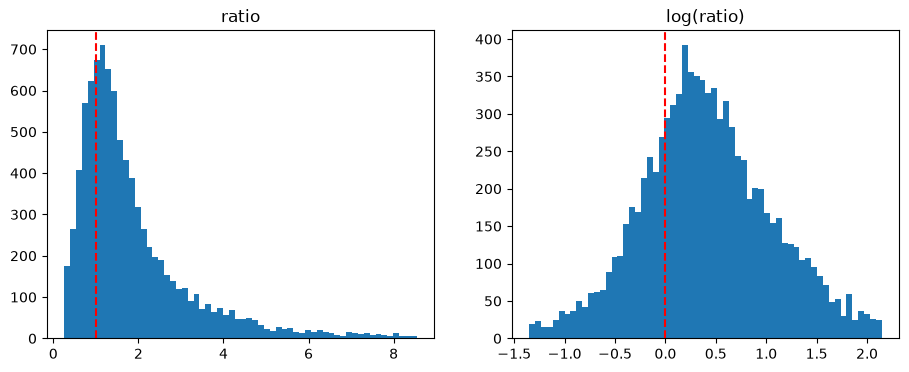

Asimetría ratio:      1.95
Asimetría log(ratio): 0.14


In [174]:
train_f1, _ = obtener_fold(df_B0, MESES_VALIDACION[0])     # train del fold 1 (jun 2025 – ene 2026)

ratio = train_f1["ratio"]
log_ratio = np.log(ratio)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(ratio, bins=60)
ax1.set_title("ratio")
ax1.axvline(1, color="red", ls="--")

ax2.hist(log_ratio, bins=60)
ax2.set_title("log(ratio)")
ax2.axvline(0, color="red", ls="--")
plt.show()

# asimetría calculada con .skew() de pandas
print("Asimetría ratio:     ", round(ratio.skew(), 2))
print("Asimetría log(ratio):", round(log_ratio.skew(), 2))

Los gráficos muestran la distribución del ratio y del log(ratio) en los datos de entrenamiento del primer fold (junio 2025 – enero 2026).

En ambas escalas se aprecia un desplazamiento hacia la derecha: la mayor parte de las fases queda por encima de ratio = 1 (log = 0). Esto refuerza el sesgo ya observado en la estimación de tiempos.

La asimetría del ratio es de 1,97, fuertemente alta. Supera el valor de 1, a partir del cual se considera una asimetría fuerte, y denota una cola larga a la derecha. El log reduce esta asimetría a 0,14, dando una distribución mucho más simétrica.

Ambas distribuciones tienen las dos colas cortadas. Esto se debe a la limpieza de outliers realizada con el corte IQR sobre el log(ratio).

Aunque el log(ratio) presente una distribución más simétrica, eso no implica que el modelo vaya a predecir mejor con esa variable. La elección entre ratio y log(ratio) se hará comparando los modelos fuera de muestra.

En el notebook 08 se inspeccionó la cola del ratio y se detectó que son las fases con tiempos previstos más bajos las que acumulan los ratios más altos.

Se guardan las predicciones de B0:

In [175]:
df_B0[["IDMOTask", "split", "mes_orden", "ratio", "pred_B0"]].to_parquet(PREDICTIONS / "b0.parquet", index=False)

## 3. B1

El análisis de B0 mostró un sesgo claro: en torno al 75 % de las fases tienen un ratio superior a 1, y el
comportamiento es estable en todos los bloques. El ERP no se equivoca por igual hacia los dos lados: en su previsión de
tiempos se queda corto de forma sistemática.

De este hallazgo surge B1, que incorpora este sesgo. En lugar de predecir ratio = 1, predice para todas las fases el
ratio típico observado en entrenamiento. Se calculan dos versiones:

- la mediana, asociada al MAE;
- la media, asociada al RMSE.

> La constante se calcula solo con el train de cada fold, igual que los modelos. En test se calcula con todo el
> conjunto de desarrollo.

Si los modelos superan a B0, puede deberse únicamente a corregir el sesgo. Superar a B1, en cambio, indica que las
variables aportan información adicional sobre la desviación de cada fase.

In [176]:
df_B1 = df[["IDMOTask", "split", "mes_orden", "ratio"]].copy()
df_B1["pred_B1_mediana"] = np.nan
df_B1["pred_B1_media"] = np.nan

filas = []
for bloque, train, evaluar in bloques_evaluacion(df, MESES_VALIDACION):
    # la constante se aprende con el train del bloque y se aplica a todas sus fases
    df_B1.loc[evaluar.index, "pred_B1_mediana"] = train["ratio"].median()
    df_B1.loc[evaluar.index, "pred_B1_media"] = train["ratio"].mean()

    d = df_B1.loc[evaluar.index]
    filas.append({"bloque":            bloque,
                  "constante_mediana": train["ratio"].median(),
                  "MAE_B1_mediana":    metricas(d["ratio"], d["pred_B1_mediana"])["MAE"],
                  "constante_media":   train["ratio"].mean(),
                  "RMSE_B1_media":     metricas(d["ratio"], d["pred_B1_media"])["RMSE"],
                  "n":                 len(d)})

resultados_B1 = pd.DataFrame(filas)
resultados_B1.round(3)

,bloque,constante_mediana,MAE_B1_mediana,constante_media,RMSE_B1_media,n
0,valid 2026-02,1.447,1.021,1.857,1.474,915
1,valid 2026-03,1.453,0.928,1.871,1.373,993
2,valid 2026-04,1.466,0.967,1.879,1.394,963
3,test,1.470,0.904,1.884,1.316,2385


- `constante_mediana`: el valor que predice B1-mediana para el ratio en todas las fases de ese bloque.
- `MAE_B1_mediana`: el MAE que se obtiene al predecir esa constante en todas las fases del bloque.
- `constante_media`: la media del ratio en el train de ese bloque.
- `RMSE_B1_media`: el RMSE que se obtiene al predecir esa constante.

```text
B1-mediana:  constante_mediana  →  MAE_B1_mediana (cuánto falla tomando la mediana)
B1-media:    constante_media    →  RMSE_B1_media  (cuánto falla tomando la media)
```

Se guardan las predicciones de B1. Las fases que solo se usan para entrenar no tienen predicción (NaN): no interesa
que la tengan, ya que solo se evalúan la validación y el test.

In [177]:
df_B1.to_parquet(PREDICTIONS / "b1.parquet", index=False)

## 4. B2

B1 compara los modelos con una única constante para todas las fases. B2 da un paso más: calcula una constante para
cada grupo de fases. Cada fase recibe la mediana (o la media) del ratio de su grupo en entrenamiento.

B2 no es un modelo, sino una tabla de consulta sencilla, como la que podría construir un planificador en una hoja de
cálculo. Ya utiliza información de las variables, pero de la forma más simple posible.

Su objetivo es comprobar si los modelos aportan algo más que esa tabla. Si un modelo supera a B2, capta información
que la tabla no recoge. Si no lo supera, una tabla por grupos sería suficiente.

> Nunca se incluye en el cálculo el mismo mes que se evalúa, ya que B2 se toma como una predicción.

### Elegir la agrupación con la que formar la tabla

Tomo el periodo de validación con menos datos de entrenamiento (fold 1) para investigar las agrupaciones:

In [178]:
train_f1, _ = obtener_fold(df, MESES_VALIDACION[0])     # train del fold 1 (jun 2025 – ene 2026)

opciones = {
    "Máquina":                ["CodigoMaquina"],
    "Familia de máquinas":    ["Familia Maquinas"],
    "Tipo de fase":           ["TipoFase"],
    "Familia × tipo de fase": ["Familia Maquinas", "TipoFase"],
}

filas = []
for nombre, cols in opciones.items():
    tamaños = train_f1.groupby(cols).size()
    filas.append({"agrupación": nombre,
                  "n_grupos": len(tamaños),
                  "grupos_<30_fases": (tamaños < 30).sum(),
                  "%_fases_en_grupos_<30": round(tamaños[tamaños < 30].sum() / len(train_f1) * 100, 1)})

pd.DataFrame(filas)

,agrupación,n_grupos,grupos_<30_fases,%_fases_en_grupos_<30
0,Máquina,24,3,0.4
1,Familia de máquinas,9,0,0.0
2,Tipo de fase,38,17,1.9
3,Familia × tipo de fase,94,69,4.1


La máquina y la familia de máquinas son las agrupaciones más interesantes para estudiar la desviación de tiempos:

- **Máquina concreta**: más detalle. Si dos tornos de la misma familia se comportan distinto, B2 lo recoge.
- **Familia**: más estable (ningún grupo pequeño), pero trata igual a todas las máquinas de una misma familia.

Se calculan las dos versiones: B2-familia y B2-máquina.

### Fallback para grupos pequeños o no vistos

B2 predice para cada fase la mediana del ratio de su grupo (familia o máquina), calculada solo con el train del fold.
Esto plantea dos problemas:

- **Grupo pequeño**: si un grupo tiene pocas fases en train, su mediana es poco fiable (ruido).
- **Grupo no visto**: si un grupo no aparece en train, no hay mediana que asignarle y el `.map()` devuelve NaN.

Para cubrir ambos casos se aplica un **fallback**. Todas las fases reciben una predicción y se evalúan; lo que cambia
es qué mediana se les asigna:

- Si su grupo tiene **≥ 30** fases en train, reciben la **mediana de su grupo**.
- Si su grupo tiene **< 30** fases en train o **no aparece**, no se usa la mediana del grupo (poco fiable o
  inexistente) y reciben la **mediana global del train**, que es la misma constante que predice B1 en ese bloque.

La idea es que B2 recurra a B1 cuando no tiene información suficiente sobre el grupo. La mediana global se calcula con
todas las fases del train, incluidas las de grupos pequeños.

Lo mismo se aplica a la versión con media: los mismos grupos caen en el fallback y reciben la media global del train
(constante de B1-media).

In [179]:
MIN_FASES = 30


def tabla_por_grupo(train, evaluar, columna):
    """B2: mediana y media del ratio de cada grupo, calculadas solo con el train.

    Los grupos con menos de MIN_FASES fases en train, o que no aparecen en él, reciben la
    constante global del train (la misma que B1).
    """
    resumen = train.groupby(columna)["ratio"].agg(["median", "mean", "size"])   # tabla de consulta
    fiables = resumen[resumen["size"] >= MIN_FASES]
    pred_mediana = evaluar[columna].map(fiables["median"])
    pred_media = evaluar[columna].map(fiables["mean"])
    n_fallback = pred_mediana.isna().sum()                  # el mismo número para la media (mismo filtro)
    return (pred_mediana.fillna(train["ratio"].median()),
            pred_media.fillna(train["ratio"].mean()),
            resumen, n_fallback)


df_B2 = df[["IDMOTask", "split", "mes_orden", "ratio"]].copy()
tablas = {"familia": {}, "maquina": {}}

for nombre, columna in [("familia", "Familia Maquinas"), ("maquina", "CodigoMaquina")]:
    df_B2[f"pred_B2_{nombre}_mediana"] = np.nan
    df_B2[f"pred_B2_{nombre}_media"] = np.nan
    print(f"B2-{nombre}:")
    for bloque, train, evaluar in bloques_evaluacion(df, MESES_VALIDACION):
        mediana, media, resumen, n_fallback = tabla_por_grupo(train, evaluar, columna)
        df_B2.loc[evaluar.index, f"pred_B2_{nombre}_mediana"] = mediana
        df_B2.loc[evaluar.index, f"pred_B2_{nombre}_media"] = media
        tablas[nombre][bloque] = resumen
        print(f"  {bloque}: {len(evaluar)} fases | {n_fallback} con fallback")

B2-familia:
  valid 2026-02: 915 fases | 0 con fallback
  valid 2026-03: 993 fases | 0 con fallback
  valid 2026-04: 963 fases | 0 con fallback
  test: 2385 fases | 0 con fallback
B2-maquina:
  valid 2026-02: 915 fases | 0 con fallback
  valid 2026-03: 993 fases | 0 con fallback
  valid 2026-04: 963 fases | 0 con fallback
  test: 2385 fases | 37 con fallback


Máquinas que reciben el fallback en test:

In [180]:
fases_maquina_dev = tablas["maquina"]["test"]["size"]
test = df[df["split"] == "test"]
con_fallback = ~test["CodigoMaquina"].isin(fases_maquina_dev[fases_maquina_dev >= MIN_FASES].index)
test.loc[con_fallback, "CodigoMaquina"].value_counts()

CodigoMaquina
CM19    36
CM18     1
Name: count, dtype: int64

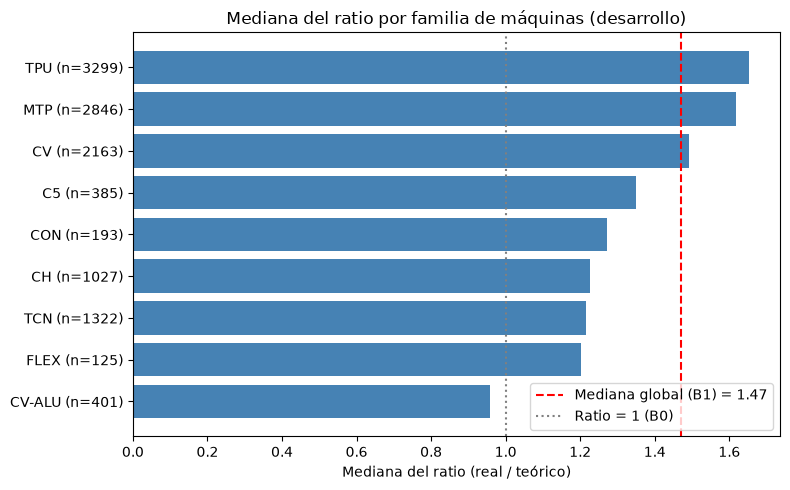

In [181]:
resumen = tablas["familia"]["test"].sort_values("median")
mediana_global_dev = df.loc[df["split"] == "desarrollo", "ratio"].median()
etiquetas = [f"{fam} (n={n})" for fam, n in zip(resumen.index, resumen["size"])]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(etiquetas, resumen["median"], color="steelblue")
ax.axvline(mediana_global_dev, color="red", linestyle="--",
           label=f"Mediana global (B1) = {mediana_global_dev:.2f}")
ax.axvline(1, color="grey", linestyle=":", label="Ratio = 1 (B0)")
ax.set_xlabel("Mediana del ratio (real / teórico)")
ax.set_title("Mediana del ratio por familia de máquinas (desarrollo)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES / "11_mediana_ratio_por_familia.png", dpi=200, bbox_inches="tight")
plt.show()

La mediana de cada familia apenas cambia entre bloques:

In [182]:
pd.concat({bloque: t["median"] for bloque, t in tablas["familia"].items()}, axis=1).round(2)

,valid 2026-02,valid 2026-03,valid 2026-04,test
Familia Maquinas,,,,
C5,1.32,1.31,1.34,1.35
CH,1.24,1.22,1.22,1.23
CON,1.32,1.30,1.27,1.27
CV,1.48,1.48,1.49,1.49
CV-ALU,0.94,0.96,0.95,0.96
FLEX,1.11,1.16,1.20,1.20
MTP,1.61,1.61,1.61,1.62
TCN,1.27,1.25,1.24,1.22
TPU,1.56,1.61,1.63,1.65


### Métricas de B2 (familia y máquina)

In [183]:
filas = []
for bloque, _, evaluar in bloques_evaluacion(df, MESES_VALIDACION):
    d = df_B2.loc[evaluar.index]
    filas.append({"bloque": bloque,
                  "MAE_B2_familia_mediana": metricas(d["ratio"], d["pred_B2_familia_mediana"])["MAE"],
                  "MAE_B2_maquina_mediana": metricas(d["ratio"], d["pred_B2_maquina_mediana"])["MAE"],
                  "RMSE_B2_familia_media":  metricas(d["ratio"], d["pred_B2_familia_media"])["RMSE"],
                  "RMSE_B2_maquina_media":  metricas(d["ratio"], d["pred_B2_maquina_media"])["RMSE"],
                  "n": len(d)})

tabla_B2 = pd.DataFrame(filas)
tabla_B2.round(3)

,bloque,MAE_B2_familia_mediana,MAE_B2_maquina_mediana,RMSE_B2_familia_media,RMSE_B2_maquina_media,n
0,valid 2026-02,0.988,0.978,1.436,1.409,915
1,valid 2026-03,0.900,0.890,1.335,1.318,993
2,valid 2026-04,0.937,0.922,1.350,1.327,963
3,test,0.882,0.862,1.285,1.262,2385


El MAE se evalúa con las predicciones de mediana y el RMSE con las de media, ya que cada una es la constante que minimiza su métrica. Los valores de MAE y RMSE no se comparan entre sí, sino cada uno con el mismo indicador de otros baselines y modelos.
    
B2 reduce el error de B1 en todos los bloques, tanto en MAE como en RMSE. Asignar un sesgo distinto a cada grupo mejora la corrección de un sesgo común para todas las fases.
     
B2-máquina obtiene menor error que B2-familia en todos los bloques, aunque la diferencia es pequeña. B2-máquina se toma como el baseline más exigente con el que comparar los modelos.

Se guardan las predicciones de B2:

In [184]:
df_B2.to_parquet(PREDICTIONS / "b2.parquet", index=False)

## 5. Escalera de baselines

Se unen los resultados de los tres baselines en una tabla:

In [185]:
escalera = (
    resultados_B0[["bloque", "MAE", "RMSE"]].rename(columns={"MAE": "MAE_B0", "RMSE": "RMSE_B0"})
    .merge(resultados_B1[["bloque", "MAE_B1_mediana", "RMSE_B1_media"]], on="bloque")
    .merge(tabla_B2.drop(columns="n"), on="bloque")
).round(3)

escalera.to_csv(TABLES / "escalera_baselines.csv", index=False)
escalera

,bloque,MAE_B0,RMSE_B0,MAE_B1_mediana,RMSE_B1_media,MAE_B2_familia_mediana,MAE_B2_maquina_mediana,RMSE_B2_familia_media,RMSE_B2_maquina_media
0,valid 2026-02,1.140,1.779,1.021,1.474,0.988,0.978,1.436,1.409
1,valid 2026-03,1.086,1.672,0.928,1.373,0.900,0.890,1.335,1.318
2,valid 2026-04,1.092,1.680,0.967,1.394,0.937,0.922,1.350,1.327
3,test,1.019,1.585,0.904,1.316,0.882,0.862,1.285,1.262


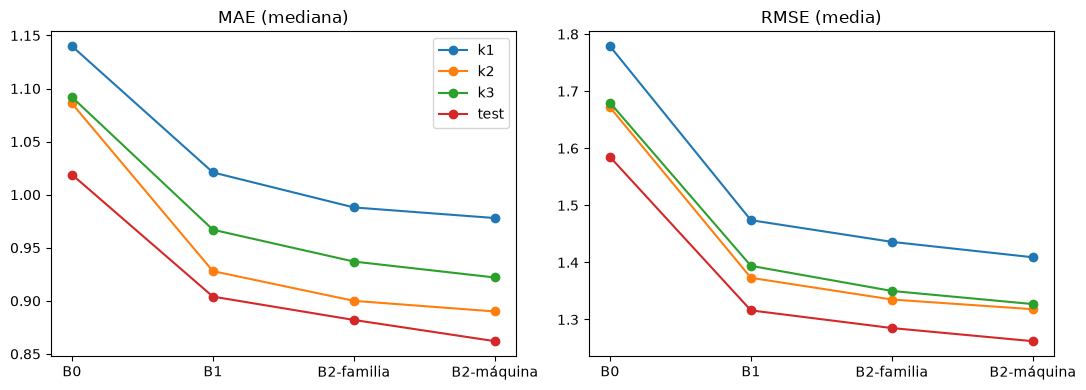

In [186]:
cols_mae  = ["MAE_B0", "MAE_B1_mediana", "MAE_B2_familia_mediana", "MAE_B2_maquina_mediana"]
cols_rmse = ["RMSE_B0", "RMSE_B1_media", "RMSE_B2_familia_media", "RMSE_B2_maquina_media"]
nombres   = ["B0", "B1", "B2-familia", "B2-máquina"]
etiquetas = ["k1", "k2", "k3", "test"]          # los 3 folds de validación y el test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for etiqueta, (_, fila) in zip(etiquetas, escalera.iterrows()):
    ax1.plot(nombres, fila[cols_mae],  marker="o", label=etiqueta)
    ax2.plot(nombres, fila[cols_rmse], marker="o", label=etiqueta)

ax1.set_title("MAE (mediana)")
ax2.set_title("RMSE (media)")
ax1.legend()
plt.tight_layout()
plt.savefig(FIGURES / "11_escalera_baselines.png", dpi=200, bbox_inches="tight")
plt.show()

En todos los bloques y en ambas métricas el error disminuye en cada escalón: B0 → B1 → B2-familia → B2-máquina. El orden entre bloques se mantiene en todos los baselines (test con el menor error, febrero con el mayor).

B2-máquina es el baseline con menor error en todos los bloques y se toma como listón principal para los modelos; B1 se mantiene como referencia para separar la corrección del sesgo global del aporte de las variables.

> Todos los errores se miden en escala ratio. Los baselines no tienen versión en log porque no la necesitan: la mediana es la constante que minimiza el MAE y la media la que minimiza el RMSE, así que ninguna otra constante, tampoco una calculada en log, puede mejorarlas en su métrica. Los modelos que entrenan con log(ratio) devuelven su predicción a escala ratio antes de evaluarse, de modo que la comparación con los baselines es directa.